# Particle PINN — fixed channel, variable injection

شعاع‌ها ثابت‌اند: **R_in=0.2, R_out=0.5**. شش پارامتر فیزیکی مدل:
`Re, diameter, density_ratio, x_p0, u_p0, v_p0`.

در ورودی کانال جریان رو به بالاست؛ موقعیت عرضی در راستای **x** است.
شبکهٔ جریان `[x,y,Re]→[u,v,p]` دارد و حرکت ذره با ODE یک‌طرفه حل می‌شود.
شرایط اولیه در رهگیری اعمال می‌شوند؛ برای تغییرشان آموزش مجدد لازم نیست.
تمام مقادیر بی‌بعدند. قطر ذره هنگام انتخاب موقعیت ورودی لحاظ می‌شود.

**Kaggle:** GPU و Internet را فعال کنید؛ Run All. سورس داخل نوت‌بوک است.
تنظیمات پیش‌فرض: سقف ۶ ساعت یا ۶۰٬۰۰۰ گام. زمان خروجی‌گیری پس از آموزش است.
وزن‌های قبلی پنج‌ورودی قابل استفاده نیستند. تست اجرا تأیید دقت نهایی نیست.


In [4]:
from pathlib import Path
import base64, hashlib, io, json, os, subprocess, sys, zipfile

BASE = Path('/kaggle/working') if Path('/kaggle/working').exists() else Path('/content') if Path('/content').exists() else Path.cwd()
ROOT = BASE / 'particle_injection_source'
ROOT.mkdir(parents=True, exist_ok=True)
SOURCE_ZIP = base64.b64decode('...')
assert hashlib.sha256(SOURCE_ZIP).hexdigest() == '31cfa70722112fa11bce1fa2cb7fcb9677fb91fb2a967688a5ba3e6c67b97766'
with zipfile.ZipFile(io.BytesIO(SOURCE_ZIP)) as archive:
    for name in archive.namelist():
        if not (ROOT / name).resolve().is_relative_to(ROOT.resolve()):
            raise RuntimeError('Invalid source archive member')
    archive.extractall(ROOT)
subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', str(ROOT / 'requirements.txt')], check=True)
sys.path.insert(0, str(ROOT))
import torch
print('Source ready:', ROOT)
print('CUDA available:', torch.cuda.is_available())
if torch.cuda.is_available(): print('GPU:', torch.cuda.get_device_name(0))


Source ready: /kaggle/working/particle_injection_source
CUDA available: True
GPU: Tesla T4


In [11]:
# All positions and velocities below are NONDIMENSIONAL.
# Fixed geometry: R_in=0.2, R_out=0.5. Inlet: y=0; cross-channel position: x_p0.
RANGES = {
    're': [0.1, 10.0],
    'diameter': [0.0025, 0.25],
    'density_ratio': [100.0, 10000.0],
    'x_p0': [-0.14, 0.14],  # horizontal inlet position; conditioned on particle radius
    'u_p0': [-0.5, 0.5],    # horizontal initial velocity
    'v_p0': [0.25, 1.5],    # vertical initial velocity; inlet flow points upward
}
DEVICE = 'cuda'  # Set Kaggle accelerator to GPU, or use 'cpu' deliberately.
HOURS = 6.0     # Training cap; set None for steps only. Exports run afterwards.
STEPS = 10000
SAMPLES = 1024
WIDTH, DEPTH = 128, 6
CHECK_EVERY = 1000
SEED = 42
RANDOM_PARTICLES = 12
SWEEP_COUNT = 5
TMAX = 10.0
SKIP_FEM = False
RESUME = None   # Optional path to this version's checkpoint.pt; keep training settings identical.

from particle_pinn.injection import ParameterRanges
ParameterRanges(**{k: tuple(v) for k,v in RANGES.items()}).validate()
print('Fixed radii: 0.2, 0.5 | Flow MLP: 3 inputs | Model: 6 physical parameters')


Fixed radii: 0.2, 0.5 | Flow MLP: 3 inputs | Model: 6 physical parameters


In [12]:
from datetime import datetime, timezone
if DEVICE == 'cuda' and not torch.cuda.is_available():
    raise RuntimeError('Enable a GPU in notebook settings, or deliberately set DEVICE to cpu.')
RUN = BASE / ('injection_' + datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%S_%fZ'))
command = [sys.executable, '-u', str(ROOT / 'run_injection_pinn.py'), '--out', str(RUN),
    '--device', DEVICE, '--steps', str(STEPS), '--samples', str(SAMPLES),
    '--width', str(WIDTH), '--depth', str(DEPTH), '--check-every', str(CHECK_EVERY),
    '--seed', str(SEED), '--particles', str(RANDOM_PARTICLES), '--sweep-count', str(SWEEP_COUNT),
    '--tmax', str(TMAX)]
if HOURS is not None: command += ['--hours', str(HOURS)]
if SKIP_FEM: command += ['--skip-reference']
if RESUME: command += ['--resume', str(RESUME)]
for key, limits in RANGES.items():
    command += ['--' + key.replace('_', '-') + '-range', *map(str, limits)]
RUN.mkdir(parents=True, exist_ok=False)
# The runner requires an empty output directory, so preserve source/log only after it starts.
log_path = BASE / (RUN.name + '.log')
print('Training output:', RUN, flush=True)
with log_path.open('w') as log:
    with subprocess.Popen(command, cwd=ROOT, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
                          text=True, bufsize=1) as process:
        for line in process.stdout:
            print(line, end='', flush=True)
            log.write(line)
            log.flush()
        status = process.wait()
(RUN / 'training_source.zip').write_bytes(SOURCE_ZIP)
import shutil
shutil.copy2(log_path, RUN / 'training.log')
if (RUN / 'run_complete.json').exists(): print((RUN / 'run_complete.json').read_text())
if status:
    print('Inspect failures.json and training.log. Partial outputs can be downloaded with the last cell.')
    raise RuntimeError('Pipeline returned exit code ' + str(status))


Training output: /kaggle/working/injection_20261031T145244_117126Z
{"event": "TRAINING_STARTED", "fixed_radii": [0.2, 0.5], "ranges": {"re": [0.1, 10.0], "diameter": [0.0025, 0.25], "density_ratio": [100.0, 10000.0], "x_p0": [-0.14, 0.14], "u_p0": [-0.5, 0.5], "v_p0": [0.25, 1.5]}, "flow_inputs": 3, "physical_parameters": 6, "device": "cuda"}
{"event": "FIXED_PROBE", "step": 0, "loss": 0.654672384262085, "best_step": 0}
{"step": 1, "elapsed_seconds": 0.5906778879998456, "total": 0.8676574230194092, "continuity": 1.7092193957068957e-05, "momentum": 0.8672133088111877, "flux": 2.045136170636397e-05, "lr": 0.0004999999879097347}
{"step": 100, "elapsed_seconds": 11.184611826000037, "total": 0.5800558924674988, "continuity": 0.0021677352488040924, "momentum": 0.5317338705062866, "flux": 0.0009934664703905582, "lr": 0.0004998791072896042}
{"step": 200, "elapsed_seconds": 22.040028947999872, "total": 0.4171833395957947, "continuity": 0.0027060527354478836, "momentum": 0.34293514490127563, "fl

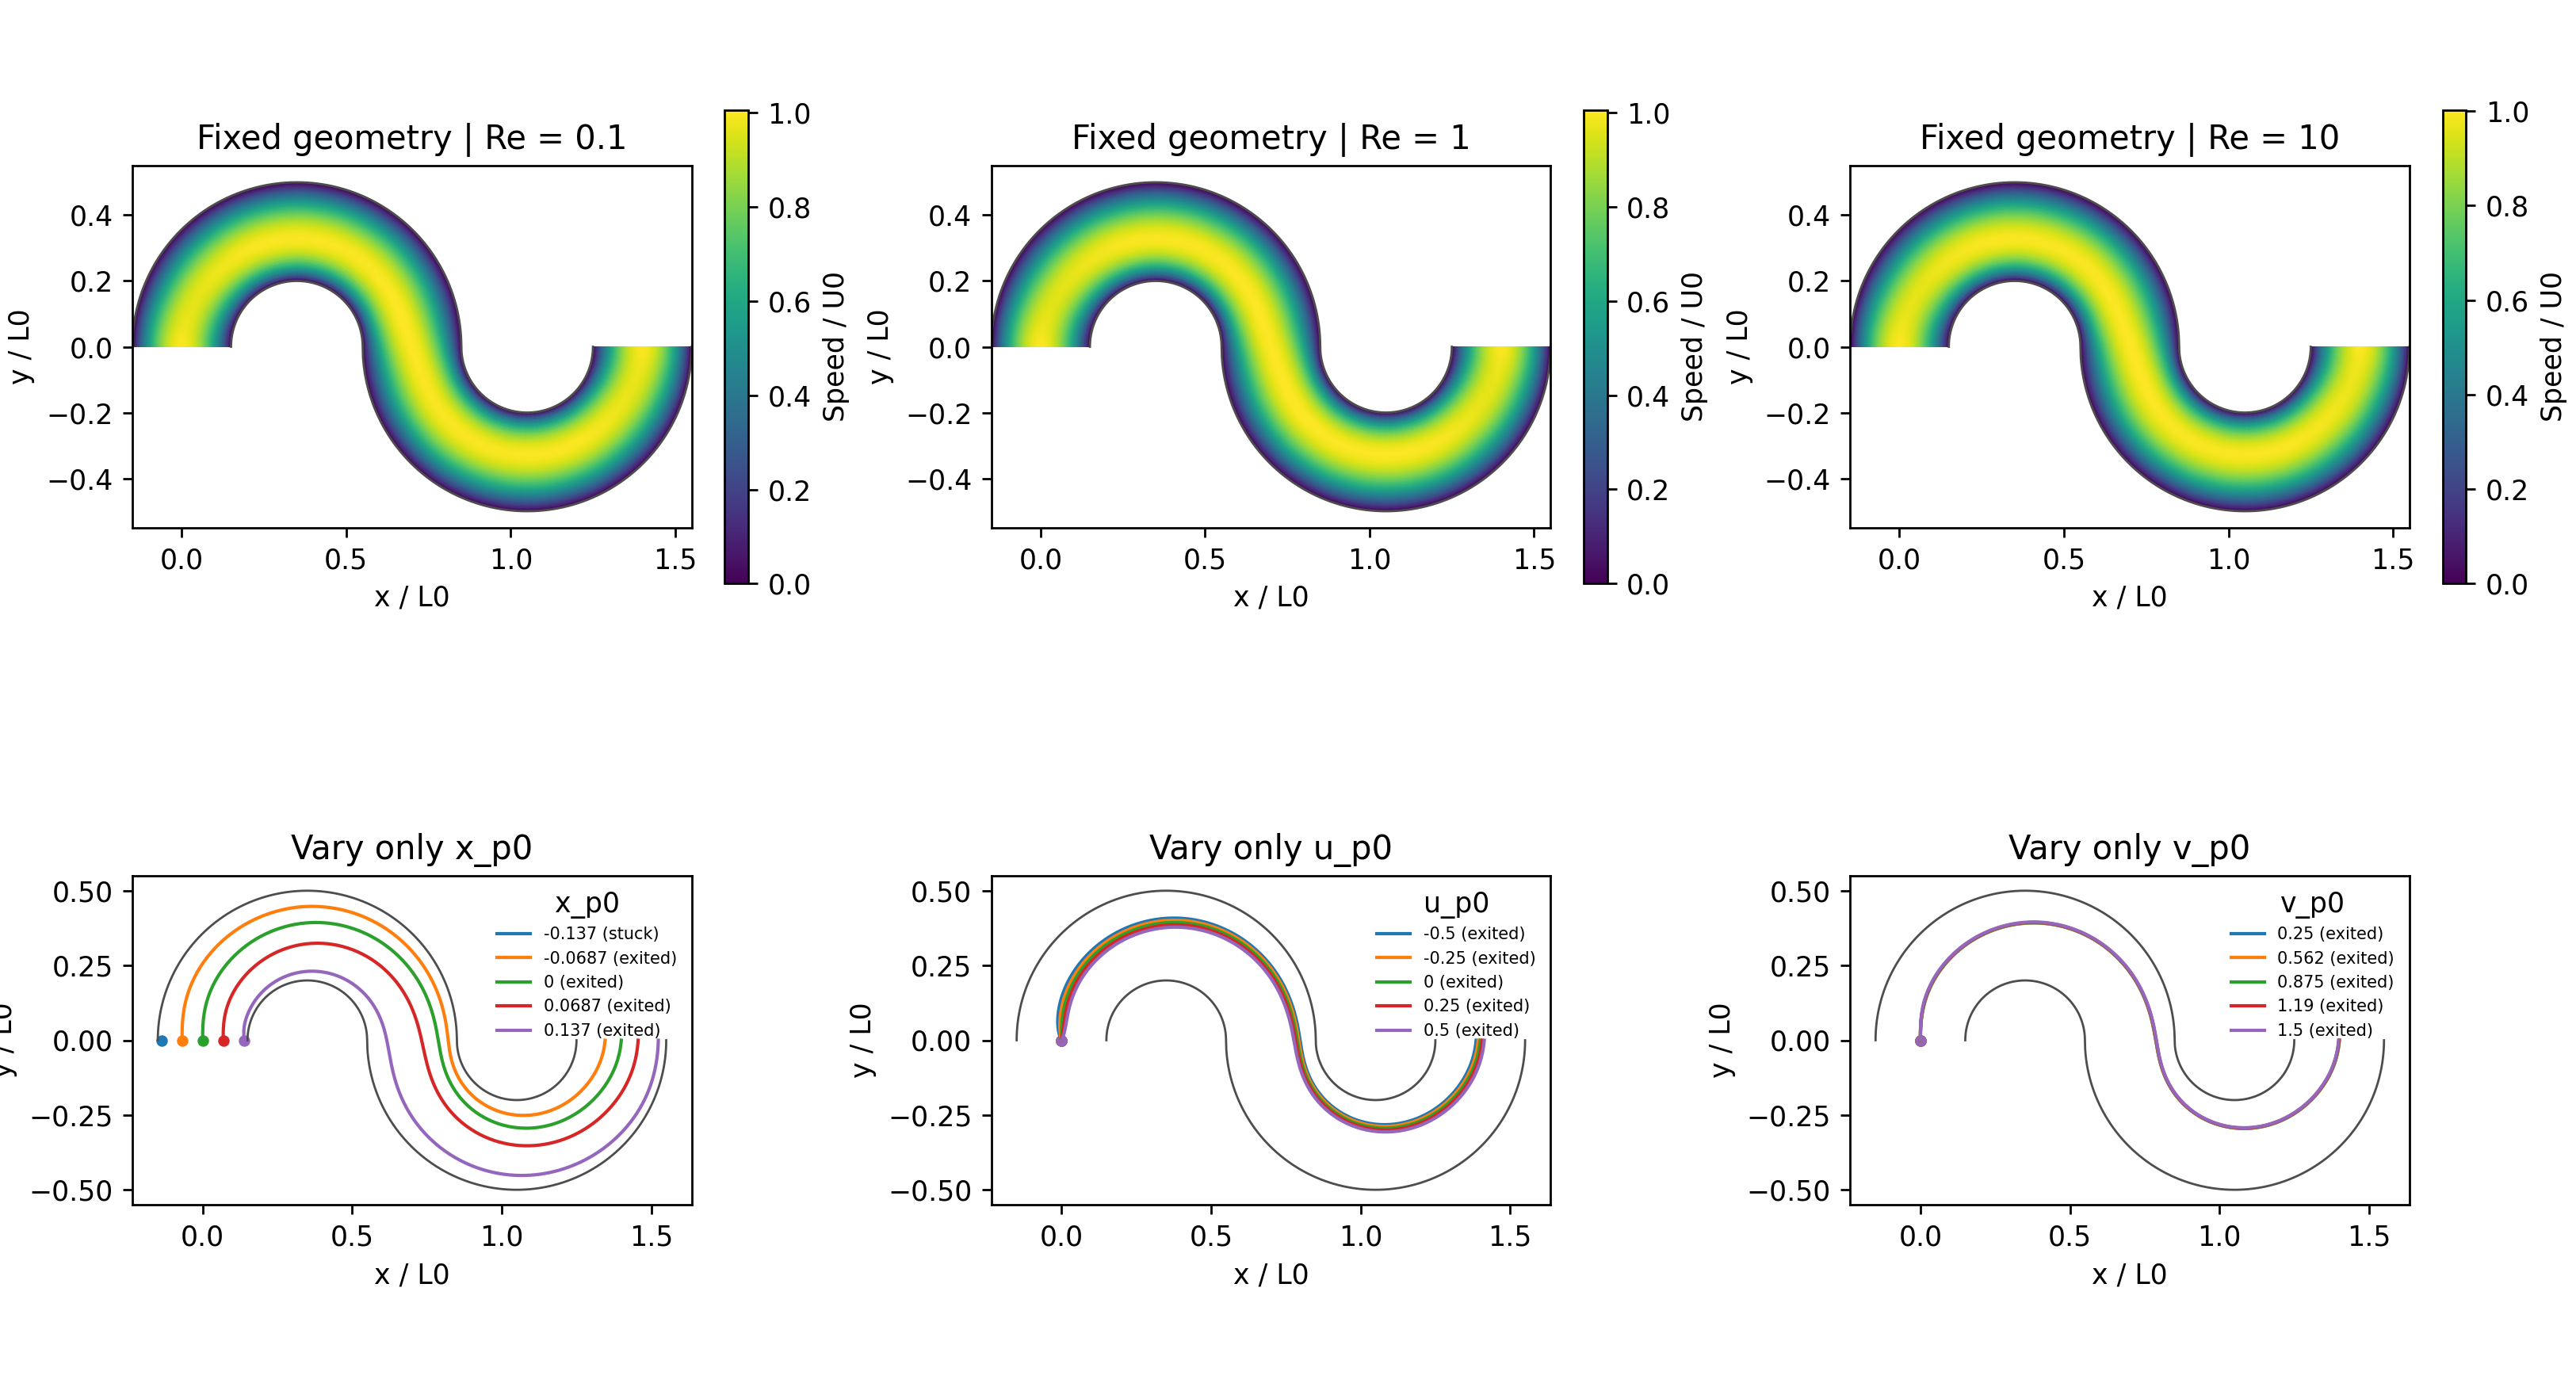

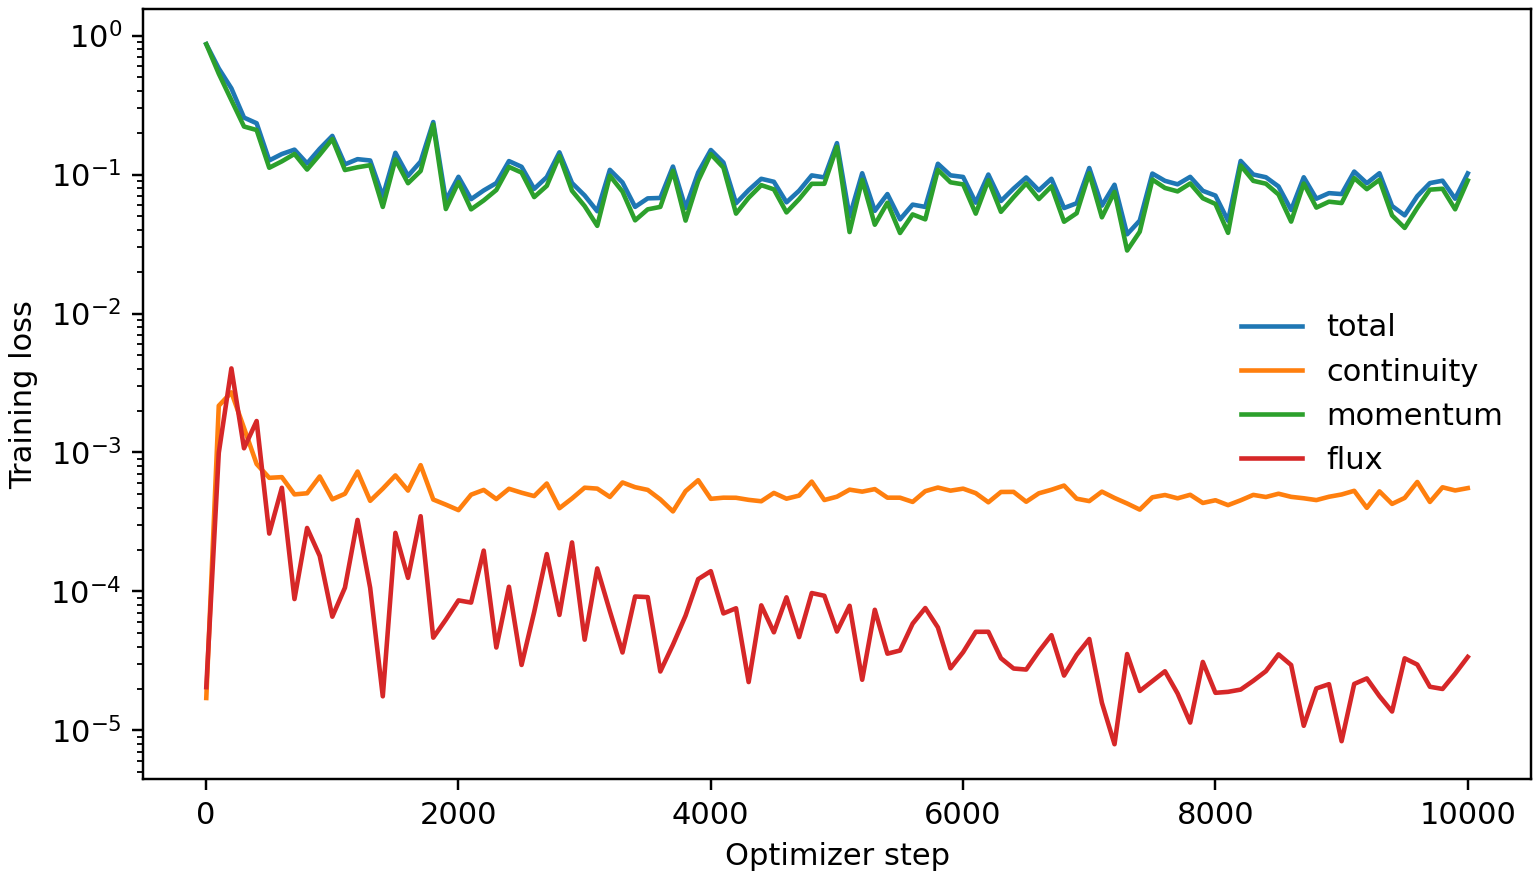

{
  "completed": [
    {
      "re": 0.1,
      "velocity_relative_l2": 0.022870090237972936,
      "pressure_relative_l2": 0.013229111499013322,
      "reference": {
        "ns": 64,
        "nn": 14,
        "triangles": 1638,
        "velocity_dofs": 6858,
        "pressure_dofs": 896,
        "iterations": 13,
        "relative_update": 4.063731085504727e-09,
        "nonlinear_residual": 1.0819797655476179e-10,
        "divergence_l2": 0.06796773849651988,
        "solver_ok": true,
        "updates": [
          0.9921092146692883,
          0.1984218566061481,
          0.039684379360402484,
          0.007936878486070493,
          0.0015873764179607133,
          0.00031747546733395995,
          6.349513807111846e-05,
          1.2699038206169028e-05,
          2.539810036999531e-06,
          5.079625482767241e-07,
          1.0159257806447519e-07,
          2.031854637479734e-08,
          4.063731085504727e-09
        ]
      }
    },
    {
      "re": 1.0,
      "velocit

In [13]:
from IPython.display import Image, display
for name in ['injection_summary.png', 'training_loss.png']:
    if (RUN / name).exists(): display(Image(filename=str(RUN / name), width=1200))
if (RUN / 'validation.json').exists(): print((RUN / 'validation.json').read_text())
print('Weights:', RUN / 'best_model.pt')


## مسیر دلخواه پس از آموزش
این سلول اختیاری است؛ شش مقدار case را تغییر دهید.


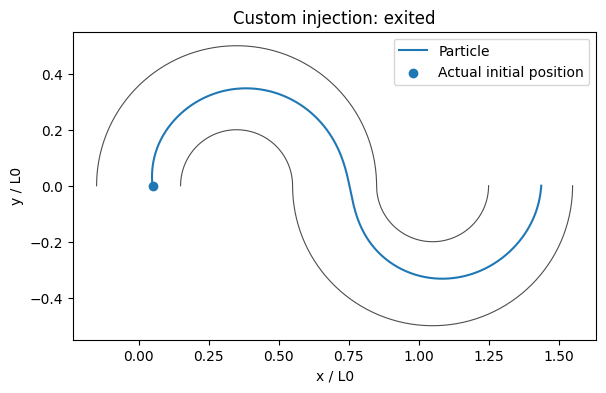

Initial state: [ 0.05  0.   -0.1   0.7 ] | Outcome: exited


In [14]:
# Change these six physical parameters AFTER training; no retraining is needed for initial data.
from particle_pinn.injection import InjectionCase, load_injection_model, trace_injection
import csv
import matplotlib.pyplot as plt

model, config = load_injection_model(RUN / 'best_model.pt', device='cpu')
case = InjectionCase(re=1.0, diameter=0.025, density_ratio=1000.0,
                     x_p0=0.05, u_p0=-0.1, v_p0=0.7).validate()
if not config['ranges']['re'][0] <= case.re <= config['ranges']['re'][1]:
    raise ValueError('Choose a Reynolds number inside the trained range.')
track = trace_injection(lambda xy: model.evaluate(xy, case), case, tmax=TMAX)
with (RUN / 'custom_trajectory.csv').open('w', newline='') as stream:
    writer = csv.writer(stream)
    writer.writerow(['t', 'x', 'y', 'u_p', 'v_p'])
    writer.writerows([[float(t), *map(float, z)] for t,z in zip(track['t'], track['state'])])
(RUN / 'custom_case.json').write_text(json.dumps(case.json(), indent=2))
from run_injection_pinn import draw_walls
fig, ax = plt.subplots(figsize=(9,4))
draw_walls(ax)
ax.plot(track['state'][:,0], track['state'][:,1], label='Particle')
ax.scatter([case.x_p0], [0], label='Actual initial position')
ax.legend()
ax.set_title('Custom injection: ' + track['outcome'])
fig.savefig(RUN / 'custom_trajectory.png', dpi=220, bbox_inches='tight')
plt.show()
print('Initial state:', track['state'][0], '| Outcome:', track['outcome'])


In [15]:
import shutil
archive = shutil.make_archive(str(RUN), 'zip', root_dir=RUN)
print('Results archive:', archive)
try:
    from google.colab import files
    files.download(archive)
except ImportError:
    from IPython.display import FileLink, display
    display(FileLink(archive))


Results archive: /kaggle/working/injection_20261031T145244_117126Z.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [10]:
# Paste this entire file into ONE new code cell after the completed training notebook.
from pathlib import Path
import sys, json, html, time
import numpy as np
from IPython.display import HTML, display, FileLink

# Settings for this viewer (all nondimensional). No training is performed.
VIEW_RE = 1.0
VIEW_DIAMETER = 0.025
VIEW_DENSITY_RATIO = 1000.0
VIEW_TMAX = 10.0
NQ, NETA = 401, 81  # Increase for a finer velocity lookup table.
if not np.isfinite(VIEW_TMAX) or VIEW_TMAX <= 0 or min(NQ, NETA) < 3:
    raise ValueError('VIEW_TMAX must be positive; NQ and NETA must be at least 3.')

_source = Path(globals().get('ROOT', '/kaggle/working/particle_injection_source'))
if not (_source / 'particle_pinn/injection.py').exists():
    raise FileNotFoundError('Run the source/setup cell of the original notebook first.')
sys.path.insert(0, str(_source))
from particle_pinn.injection import load_injection_model, InjectionCase, HALF_WIDTH, RADIUS, LENGTH
from particle_pinn.parametric import map_points
import torch

_run = Path(globals()['RUN']) if 'RUN' in globals() else None
if _run is None or not (_run / 'best_model.pt').exists():
    _files = list(Path('/kaggle/working').glob('injection_*/best_model.pt'))
    if not _files:
        raise FileNotFoundError('No best_model.pt found. Set RUN to your completed output folder.')
    _run = max(_files, key=lambda p: p.stat().st_mtime).parent
_view_model, _cfg = load_injection_model(_run / 'best_model.pt', device='cpu')
_ranges = _cfg['ranges']
for _key, _val in [('re', VIEW_RE), ('diameter', VIEW_DIAMETER), ('density_ratio', VIEW_DENSITY_RATIO)]:
    if not _ranges[_key][0] <= _val <= _ranges[_key][1]:
        raise ValueError(f'{_key}={_val} is outside the saved range {_ranges[_key]}. Edit viewer settings.')
_clear = HALF_WIDTH - VIEW_DIAMETER / 2 - 1e-7
_xrange = [max(_ranges['x_p0'][0], -_clear), min(_ranges['x_p0'][1], _clear)]
if _xrange[0] > _xrange[1]:
    raise ValueError('No admissible inlet position for this particle diameter.')

_q, _eta = torch.meshgrid(torch.linspace(0, 1, NQ), torch.linspace(-1, 1, NETA), indexing='ij')
_p = _view_model.geometry_parameters(torch.full((_q.numel(), 1), VIEW_RE))
_xy = map_points(_q.flatten(), _eta.flatten(), _p).numpy()
_uv = np.concatenate([_view_model.evaluate(_xy[k:k+2048], VIEW_RE)[:, :2]
                      for k in range(0, len(_xy), 2048)]).reshape(NQ, NETA, 2)
if not np.isfinite(_uv).all():
    raise ValueError('The loaded model produced a non-finite velocity field.')

# Measure lookup interpolation error against the actual trained PINN, not CFD.
_rng = np.random.default_rng(902)
_qq = _rng.uniform(0, 1, 1000); _ee = _rng.uniform(-.99, .99, 1000)
_pp = _view_model.geometry_parameters(torch.full((1000, 1), VIEW_RE))
_testxy = map_points(torch.tensor(_qq, dtype=torch.float32), torch.tensor(_ee, dtype=torch.float32), _pp).numpy()
_truth = _view_model.evaluate(_testxy, VIEW_RE)[:, :2]
_a, _b = _qq*(NQ-1), (_ee+1)*.5*(NETA-1)
_i, _j = np.minimum(_a.astype(int), NQ-2), np.minimum(_b.astype(int), NETA-2)
_f, _g = (_a-_i)[:, None], (_b-_j)[:, None]
_interp = ((1-_f)*(1-_g)*_uv[_i,_j] + _f*(1-_g)*_uv[_i+1,_j]
           + (1-_f)*_g*_uv[_i,_j+1] + _f*_g*_uv[_i+1,_j+1])
_lookup_error = float(np.linalg.norm(_interp-_truth)/max(np.linalg.norm(_truth), 1e-12))
print('Loaded:', _run / 'best_model.pt')
print(f'Lookup vs trained PINN relative L2: {_lookup_error:.3%}; no retraining.')
if _lookup_error > .01:
    print('Lookup error > 1%. Increase NQ and NETA and rerun this viewer cell.')
_D = dict(nq=NQ, ne=NETA, uv=_uv.reshape(-1).round(7).tolist(), re=VIEW_RE,
          diameter=VIEW_DIAMETER, density=VIEW_DENSITY_RATIO, tmax=VIEW_TMAX,
          xr=_xrange, ur=_ranges['u_p0'], vr=_ranges['v_p0'], lookup_error=_lookup_error)

_page = r'''<!doctype html><html lang="fa" dir="rtl"><meta charset="utf-8">
<meta name="viewport" content="width=device-width,initial-scale=1">
<title>Particle launch lab</title>
<style>
*{box-sizing:border-box}body{margin:0;background:#0b1220;color:#e6edf6;font:14px system-ui,sans-serif}
main{max-width:1280px;margin:auto;padding:20px}h2{margin:0 0 8px;font-size:23px}p{color:#aebed2;line-height:1.8}
.layout{display:grid;grid-template-columns:360px 1fr;gap:16px;direction:ltr}.panel{background:#121f32;border:1px solid #26384f;border-radius:16px;padding:16px;direction:rtl}
canvas{width:100%;display:block;touch-action:none}#launch{cursor:crosshair;border-radius:10px;background:#0b1627}#view{height:440px}
label{display:flex;justify-content:space-between;gap:8px;margin:14px 0 4px}output{font:13px monospace;color:#63e4c6;direction:ltr}
input[type=range]{width:100%;direction:ltr;accent-color:#54d9bc}button{border:0;border-radius:9px;padding:10px 15px;background:#39c7ad;color:#071a1b;cursor:pointer;font:inherit}
button.alt{background:#26394f;color:#e6edf6}.row{display:flex;gap:8px;flex-wrap:wrap;margin-top:14px}.status{min-height:44px;margin-top:12px;color:#b9cddd;line-height:1.7}
.small{font-size:12px;color:#9eb0c9;line-height:1.8}#meta{direction:ltr;text-align:left}a{color:#63e4c6}
@media(max-width:800px){.layout{grid-template-columns:1fr}#view{height:340px}}
</style><main>
<h2>آزمایشگاه حرکت ذره</h2><p>روی نوار ورودی کلیک کن و ماوس را بکش؛ طول و جهت پیکان، سرعت اولیه را تعیین می‌کند. با رهاکردن ماوس مسیر محاسبه می‌شود.</p>
<div class="layout"><section class="panel">
<canvas id="launch" width="360" height="280" aria-label="انتخاب نقطه و کشیدن بردار سرعت"></canvas>
<label>موقعیت عرضی ورودی <output id="xo"></output></label><input id="x" type="range" aria-label="موقعیت عرضی">
<label>سرعت افقی اولیه <output id="uo"></output></label><input id="u" type="range" aria-label="سرعت افقی">
<label>سرعت عمودی اولیه <output id="vo"></output></label><input id="v" type="range" aria-label="سرعت عمودی">
<div class="row"><button id="replay">پخش دوباره</button><button class="alt" id="pause">توقف / ادامه</button><button class="alt" id="csv">دریافت مسیر CSV</button></div>
<div id="status" class="status" role="status"></div><div id="meta" class="small"></div>
</section><section class="panel"><canvas id="view" aria-label="کانال و مسیر متحرک ذره"></canvas>
<div class="small">موقعیت شروع روی مقطع ورودی y=0 انتخاب می‌شود. همهٔ مقادیر بی‌بعدند. رنگ زمینه: اندازهٔ سرعت سیال؛ نقطه: ذره با قطر انتخاب‌شده.</div>
<div class="small">نمایش سریع از جدول سرعتِ استخراج‌شده از PINN آموزش‌دیده و حل حرکت در مرورگر استفاده می‌کند. نیرو: درگ Schiller–Naumann؛ پایان مسیر در تماس دیواره یا خروج.</div></section></div></main>
<script>
const D=__DATA__;
// PHYSICS_START
const R=.35,H=.15,L=2*Math.PI*R,clamp=(x,a,b)=>Math.max(a,Math.min(b,x));
function map(q,e){let second=q>.5,a=2*Math.PI*q-(second?Math.PI:0),s=Math.sin(a),c=Math.cos(a);if(q===0||q===.5||q===1)s=0;
return second?[3*R-R*c+H*e*c,-R*s+H*e*s]:[R-R*c-H*e*c,R*s+H*e*s];}
function coords(x,y){let second=x>3*R||(x>=R&&y<0),dx=x-(second?3*R:R),dy=second?-y:y;
let a=Math.PI-Math.atan2(Math.max(dy,0),dx),s=(second?a+Math.PI:a)*R,rad=Math.hypot(dx,y),e=(second?R-rad:rad-R)/H;
if(x<R&&y<0){s=y;e=-x/H;}if(x>3*R&&y>0){s=L+y;e=(x-4*R)/H;}return[s,e];}
function fluid(z){let [s,e]=coords(z[0],z[1]),a=clamp(s/L,0,1)*(D.nq-1),b=(clamp(e,-1,1)+1)*.5*(D.ne-1);
let i=Math.min(Math.floor(a),D.nq-2),j=Math.min(Math.floor(b),D.ne-2),f=a-i,g=b-j,out=[0,0];
for(let k=0;k<2;k++){let p=2*(i*D.ne+j)+k;out[k]=(1-f)*(1-g)*D.uv[p]+f*(1-g)*D.uv[p+2*D.ne]+(1-f)*g*D.uv[p+2]+f*g*D.uv[p+2*D.ne+2];}return out;}
function rate(U,V){let rep=D.re*D.diameter*Math.hypot(U[0]-V[0],U[1]-V[1]),f=rep<1000?1+.15*Math.pow(rep,.687):.44*rep/24;
return 18*f/(D.density*D.re*D.diameter*D.diameter);}
function frozen(z,U,k,h){let decay=Math.exp(-k*h),b=-Math.expm1(-k*h)/k;
return[z[0]+U[0]*h+(z[2]-U[0])*b,z[1]+U[1]*h+(z[3]-U[1])*b,U[0]+(z[2]-U[0])*decay,U[1]+(z[3]-U[1])*decay];}
function step(z,h){let U=fluid(z),mid=frozen(z,U,rate(U,z.slice(2)),h/2),Um=fluid(mid);
return frozen(z,Um,rate(Um,mid.slice(2)),h);}
function integrate(x,u,v){let z=[x,0,u,v],t=0,dt=.002,rows=[[0,...z]],outcome='time_limit',attempts=0;
if(v<0)return{rows,outcome:'backflow_exit'};
while(t<D.tmax){if(++attempts>80000)throw Error('بودجهٔ محاسبه تمام شد؛ زمان نمایش را کمتر کن.');
let h=Math.min(dt,D.tmax-t,.01/Math.max(1,Math.hypot(z[2],z[3])));if(h<1e-12)break;
let coarse=step(z,h),half=step(z,h/2),fine=step(half,h/2),err=0;
for(let k=0;k<4;k++){let scale=(k<2?2e-7:2e-6)+2e-5*Math.max(Math.abs(z[k]),Math.abs(fine[k]));err=Math.max(err,Math.abs(fine[k]-coarse[k])/(3*scale));}
if(!fine.every(Number.isFinite)||!Number.isFinite(err))throw Error('حل حرکت به مقدار نامعتبر رسید.');
if(err>1){dt=h*Math.max(.15,.85*Math.pow(err,-1/3));continue;}
let [s,e]=coords(fine[0],fine[1]),tests=[];
if(H*(1-Math.abs(e))-D.diameter/2<=0)tests.push(['stuck',a=>H*(1-Math.abs(coords(a[0],a[1])[1]))-D.diameter/2]);
if(s>=L)tests.push(['exited',a=>L-coords(a[0],a[1])[0]]);
if(s< -1e-12)tests.push(['backflow_exit',a=>coords(a[0],a[1])[0]]);
if(tests.length){let first=1,kind='';for(let [name,fn] of tests){let lo=0,hi=1;for(let j=0;j<32;j++){let m=(lo+hi)/2,zm=step(step(z,h*m/2),h*m/2);if(fn(zm)>0)lo=m;else hi=m;}
if(hi<=first){first=hi;kind=name;}}
z=step(step(z,h*first/2),h*first/2);t+=h*first;rows.push([t,...z]);outcome=kind;break;}
z=fine;t+=h;rows.push([t,...z]);dt=h*(err>1e-12?clamp(.9*Math.pow(err,-1/3),.5,2):2);}
return{rows,outcome};}
// PHYSICS_END
const $=id=>document.getElementById(id),launch=$('launch'),lc=launch.getContext('2d'),view=$('view'),ctx=view.getContext('2d');
let controls={x:$('x'),u:$('u'),v:$('v')},ranges={x:D.xr,u:D.ur,v:D.vr};
for(let k of ['x','u','v']){controls[k].min=ranges[k][0];controls[k].max=ranges[k][1];controls[k].step=Math.max((ranges[k][1]-ranges[k][0])/2000,1e-7);}
controls.x.value=clamp(0,...D.xr);controls.u.value=clamp(0,...D.ur);controls.v.value=clamp(1,...D.vr);
let trajectory=null,clock=0,last=null,paused=false,pending=0,dragging=false,back=document.createElement('canvas'),transform=null;
const gain=Math.min(100,210/Math.max(.1,Math.max(0,D.vr[1])-Math.min(0,D.vr[0]))),baseY=30+Math.max(0,D.vr[1])*gain;
function values(){return['x','u','v'].map(k=>Number(controls[k].value));}
function arrow(c,x,y,dx,dy,color){let a=Math.atan2(dy,dx);c.strokeStyle=color;c.fillStyle=color;c.lineWidth=2;c.beginPath();c.moveTo(x,y);c.lineTo(x+dx,y+dy);c.stroke();c.beginPath();c.moveTo(x+dx,y+dy);c.lineTo(x+dx-9*Math.cos(a-.45),y+dy-9*Math.sin(a-.45));c.lineTo(x+dx-9*Math.cos(a+.45),y+dy-9*Math.sin(a+.45));c.fill();}
function launchDraw(){let[x,u,v]=values();$('xo').textContent=x.toFixed(4);$('uo').textContent=u.toFixed(4);$('vo').textContent=v.toFixed(4);
lc.clearRect(0,0,360,280);let a=180+950*D.xr[0],b=180+950*D.xr[1];lc.strokeStyle='#526b88';lc.lineWidth=7;lc.beginPath();lc.moveTo(a,baseY);lc.lineTo(b,baseY);lc.stroke();
lc.fillStyle='#aebed2';lc.font='12px sans-serif';lc.textAlign='center';lc.fillText('x_p0   •   ورودی کانال',180,Math.min(273,baseY+35));
let px=180+950*x;arrow(lc,px,baseY,gain*u,-gain*v,'#63e4c6');lc.fillStyle='#ffcd75';lc.beginPath();lc.arc(px,baseY,6,0,7);lc.fill();}
function pathWalls(c){for(let e of [-1,1]){c.beginPath();for(let i=0;i<=500;i++){let p=transform(map(i/500,e));if(i===0)c.moveTo(...p);else c.lineTo(...p);}c.stroke();}}
function resize(){let w=Math.max(300,view.clientWidth),h=view.clientHeight||440,dpr=Math.min(2,window.devicePixelRatio||1);view.width=w*dpr;view.height=h*dpr;ctx.setTransform(dpr,0,0,dpr,0,0);
back.width=view.width;back.height=view.height;let c=back.getContext('2d');c.setTransform(dpr,0,0,dpr,0,0);
let scale=Math.min((w-50)/1.85,(h-70)/1.10),ox=(w-scale*1.4)/2,oy=h/2;transform=p=>[ox+p[0]*scale,oy-p[1]*scale];transform.scale=scale;
c.fillStyle='#0c1728';c.fillRect(0,0,w,h);let vmax=0;for(let i=0;i<D.uv.length;i+=2)vmax=Math.max(vmax,Math.hypot(D.uv[i],D.uv[i+1]));
for(let i=0;i<D.nq-1;i+=2)for(let j=0;j<D.ne-1;j+=2){let k=2*(i*D.ne+j),s=Math.hypot(D.uv[k],D.uv[k+1])/Math.max(vmax,1e-12);
c.fillStyle=`hsl(${225-65*s},65%,${16+22*s}%)`;let corners=[[i,j],[Math.min(i+2,D.nq-1),j],[Math.min(i+2,D.nq-1),Math.min(j+2,D.ne-1)],[i,Math.min(j+2,D.ne-1)]];
c.beginPath();corners.forEach(([ii,jj],n)=>{let p=transform(map(ii/(D.nq-1),2*jj/(D.ne-1)-1));if(!n)c.moveTo(...p);else c.lineTo(...p);});c.closePath();c.fill();}
c.strokeStyle='#8fa6c2';c.lineWidth=1.2;pathWalls(c);c.fillStyle='#bdcce0';c.font='12px sans-serif';let p=transform([0,0]);c.fillText('inlet',p[0]-15,p[1]+25);
p=transform([4*R,0]);c.fillText('outlet',p[0]-15,p[1]-15);draw();}
function draw(){if(!transform)return;let dpr=Math.min(2,window.devicePixelRatio||1);ctx.clearRect(0,0,view.clientWidth,view.clientHeight);ctx.drawImage(back,0,0,back.width/dpr,back.height/dpr);
let[x,u,v]=values(),p=transform([x,0]);arrow(ctx,...p,u*45,-v*45,'#63e4c6');
if(!trajectory)return;let rows=trajectory.rows;ctx.strokeStyle='#ffcd7566';ctx.lineWidth=1.5;ctx.beginPath();rows.forEach((r,i)=>{let p=transform(r.slice(1,3));if(!i)ctx.moveTo(...p);else ctx.lineTo(...p);});ctx.stroke();
let i=0;while(i<rows.length-2&&rows[i+1][0]<clock)i++;let a=rows[i],b=rows[Math.min(i+1,rows.length-1)],f=b[0]>a[0]?clamp((clock-a[0])/(b[0]-a[0]),0,1):0;
let z=[a[1]+f*(b[1]-a[1]),a[2]+f*(b[2]-a[2])];p=transform(z);ctx.fillStyle='#ffcd75';ctx.beginPath();ctx.arc(...p,Math.max(2.5,D.diameter*transform.scale/2),0,7);ctx.fill();
ctx.fillStyle='#dae8f7';ctx.font='13px monospace';ctx.fillText('t* = '+Math.min(clock,rows[rows.length-1][0]).toFixed(3),18,24);}
function replay(){clock=0;last=null;paused=false;draw();}
function compute(){clearTimeout(pending);$('status').textContent='در حال محاسبه…';setTimeout(()=>{try{let start=performance.now();trajectory=integrate(...values());replay();
let names={stuck:'تماس با دیواره',exited:'خروج از کانال',backflow_exit:'خروج از ورودی',time_limit:'پایان زمان محاسبه'};
$('status').textContent=names[trajectory.outcome]+' | زمان محاسبه: '+Math.round(performance.now()-start)+' ms';}catch(e){trajectory=null;$('status').textContent=e.message;}draw();},20);}
for(let k of ['x','u','v'])controls[k].addEventListener('input',()=>{launchDraw();trajectory=null;draw();clearTimeout(pending);pending=setTimeout(compute,160);});
function pointer(ev){let b=launch.getBoundingClientRect();return[(ev.clientX-b.left)*360/b.width,(ev.clientY-b.top)*280/b.height];}
launch.addEventListener('pointerdown',ev=>{let[p,y]=pointer(ev),[x,u,v]=values(),tip=[180+950*x+gain*u,baseY-gain*v];
if(Math.abs(y-baseY)<25)controls.x.value=clamp((p-180)/950,...D.xr);else if(Math.hypot(p-tip[0],y-tip[1])>25)return;
dragging=true;launch.setPointerCapture(ev.pointerId);clearTimeout(pending);trajectory=null;launchDraw();draw();});
launch.addEventListener('pointermove',ev=>{if(!dragging)return;let[p,y]=pointer(ev);controls.u.value=clamp((p-180-950*Number(controls.x.value))/gain,...D.ur);controls.v.value=clamp((baseY-y)/gain,...D.vr);launchDraw();draw();});
function release(){if(dragging){dragging=false;compute();}}launch.addEventListener('pointerup',release);launch.addEventListener('pointercancel',release);
$('replay').onclick=replay;$('pause').onclick=()=>{paused=!paused;last=null;};
$('csv').onclick=()=>{if(!trajectory)return;let[x,u,v]=values(),text=`# Re=${D.re},diameter=${D.diameter},density_ratio=${D.density},x_p0=${x},u_p0=${u},v_p0=${v},outcome=${trajectory.outcome}\nt,x,y,u_p,v_p\n`+trajectory.rows.map(r=>r.join(',')).join('\n');
let url=URL.createObjectURL(new Blob([text],{type:'text/csv'})),a=document.createElement('a');a.href=url;a.download='particle_trajectory.csv';a.click();setTimeout(()=>URL.revokeObjectURL(url),1000);};
$('meta').textContent=`Re=${D.re} | d_p=${D.diameter} | rho_p/rho_f=${D.density}\nLookup L2 vs PINN: ${(100*D.lookup_error).toFixed(3)}%`;
function tick(now){if(last!==null&&!paused&&trajectory)clock=Math.min(trajectory.rows[trajectory.rows.length-1][0],clock+Math.min(.1,(now-last)/1000));last=now;draw();requestAnimationFrame(tick);}
new ResizeObserver(resize).observe(view);launchDraw();resize();compute();requestAnimationFrame(tick);
</script></html>'''
_page = _page.replace('__DATA__', json.dumps(_D, separators=(',', ':'), allow_nan=False))
_app_path = _run.parent / 'particle_live_app.html'
_app_path.write_text(_page, encoding='utf-8')
display(HTML('<iframe title="Particle launch lab" style="width:100%;height:880px;border:0;border-radius:16px" '
             'sandbox="allow-scripts allow-downloads" srcdoc="'+html.escape(_page, quote=True)+'"></iframe>'))
print('Standalone app — also downloadable from the Kaggle Output panel:')
display(FileLink(str(_app_path)))


Loaded: /kaggle/working/injection_20261031T141523_440344Z/best_model.pt
Lookup vs trained PINN relative L2: 0.020%; no retraining.


/usr/local/lib/python3.13/dist-packages/IPython/core/display.py:724: UserWarning: Consider using IPython.display.IFrame instead
  warnings.warn("Consider using IPython.display.IFrame instead")


Standalone app — also downloadable from the Kaggle Output panel:


/kaggle/working/particle_live_app.html